# EDA: NF-UNSW-NB15-v3
Разведочный анализ датасета: баланс классов, пропуски, дубликаты, описание признаков, утечки (IP, TTL).

Данные: `python scripts/download_data.py`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 60)
df = pd.read_parquet('../data/raw/NF-UNSW-NB15-v3.parquet')
feat = pd.read_csv('../data/raw/NetFlow_v3_Features.csv')
df.shape

(2365424, 55)

In [2]:
feat.assign(Feature=feat.Feature.str.strip())

,Feature,Description
0,IPV4_SRC_ADDR,IPv4 source address
1,IPV4_DST_ADDR,IPv4 destination address
2,L4_SRC_PORT,IPv4 source port number
3,L4_DST_PORT,IPv4 destination port number
4,PROTOCOL,IP protocol identifier byte
5,L7_PROTO,Layer 7 protocol (numeric)
6,IN_BYTES,Incoming number of bytes
7,OUT_BYTES,Outgoing number of bytes
8,IN_PKTS,Incoming number of packets
9,OUT_PKTS,Outgoing number of packets


## Баланс классов

In [3]:
vc = df['Attack'].value_counts()
pd.DataFrame({'потоков': vc, 'доля, %': (100*vc/len(df)).round(3)})

,потоков,"доля, %"
Attack,,
Benign,2237731,94.602
Exploits,42748,1.807
Fuzzers,33816,1.430
Generic,19651,0.831
Reconnaissance,17074,0.722
DoS,5980,0.253
Backdoor,4659,0.197
Shellcode,2381,0.101
Analysis,1226,0.052


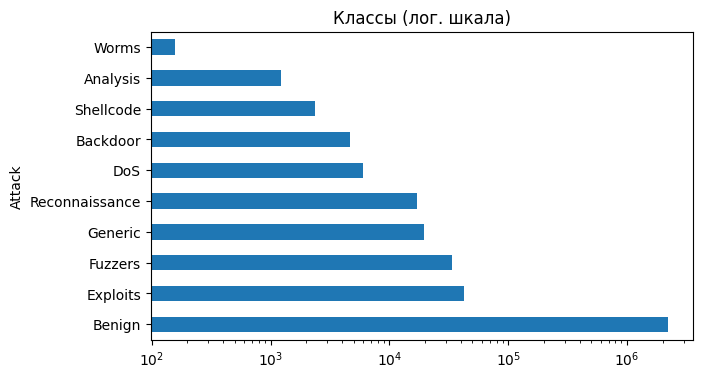

In [4]:
vc.plot.barh(logx=True, figsize=(7,4)); plt.title('Классы (лог. шкала)');

## Пропуски, бесконечности, дубликаты

In [5]:
num = df.select_dtypes('number')
print('пропуски:', df.isna().sum()[lambda s: s>0].to_dict())
print('inf:', np.isinf(num).sum()[lambda s: s>0].to_dict())
print('дубликатов:', df.duplicated().sum())

пропуски: {'SRC_TO_DST_SECOND_BYTES': 63425}


inf: {'SRC_TO_DST_SECOND_BYTES': 59068, 'DST_TO_SRC_SECOND_BYTES': 122493}


дубликатов: 14815


## Временная структура
Атаки присутствуют только в части интервалов записи — поэтому разбиение train/val/test выполняется по временным блокам (5 мин), а не случайно по потокам.

In [6]:
t = pd.to_datetime(df.FLOW_START_MILLISECONDS, unit='ms')
df.groupby([t.dt.floor('h'), 'Label']).size().unstack(fill_value=0)

Label,0,1
FLOW_START_MILLISECONDS,,
2015-01-22 11:00:00,16412,1431
2015-01-22 12:00:00,87595,9054
2015-01-22 13:00:00,89453,6977
2015-01-22 14:00:00,90933,0
2015-01-22 15:00:00,84839,0
2015-01-22 16:00:00,90840,0
2015-01-22 17:00:00,90450,0
2015-01-22 18:00:00,89087,0
2015-01-22 19:00:00,71022,0


## Признаки-утечки
Все атакующие потоки исходят из подсети 175.45.176.0/24, а TTL у атак почти всегда 62/254 — эти признаки описывают конфигурацию испытательного стенда UNSW, а не поведение атаки. IP-адреса исключаются, TTL проверяется абляцией.

In [7]:
print(df.loc[df.Label==1,'IPV4_SRC_ADDR'].str.rsplit('.',n=1).str[0].value_counts())
df.groupby('Label').MIN_TTL.value_counts(normalize=True).groupby(level=0).head(4)

IPV4_SRC_ADDR
175.45.176    127693
Name: count, dtype: int64


Label  MIN_TTL
0      31         0.985382
       0          0.012044
       29         0.001611
       1          0.000570
1      254        0.750237
       62         0.248205
       0          0.001535
       255        0.000023
Name: proportion, dtype: float64

## Описательная статистика основных признаков

In [8]:
cols = ['IN_BYTES','OUT_BYTES','IN_PKTS','OUT_PKTS','FLOW_DURATION_MILLISECONDS','L4_DST_PORT','TCP_FLAGS']
df.groupby('Label')[cols].median().T

Label,0,1
IN_BYTES,1684.0,706.0
OUT_BYTES,2511.0,256.0
IN_PKTS,19.0,10.0
OUT_PKTS,18.0,6.0
FLOW_DURATION_MILLISECONDS,28.0,528.0
L4_DST_PORT,80.0,111.0
TCP_FLAGS,27.0,19.0
